[*] Loaded Raw Train: 691,369 rows | Raw Test: 296,302 rows
[*] Generating domain features...
[*] Computing leak-free OOF Target Encodings across 5 folds...
[*] Final Feature Count for Training: 39

[*] Starting 5-Fold Training for XGBoost & LightGBM on GPU...


1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.


Fold 1 | XGB AUC: 0.96311 | LGB AUC: 0.96321
Fold 2 | XGB AUC: 0.96365 | LGB AUC: 0.96378
Fold 3 | XGB AUC: 0.96379 | LGB AUC: 0.96395
Fold 4 | XGB AUC: 0.96471 | LGB AUC: 0.96448
Fold 5 | XGB AUC: 0.96372 | LGB AUC: 0.96381

  Overall OOF XGBoost AUC:        0.96379
  Overall OOF LightGBM AUC:       0.96383
  FINAL 50/50 RANK ENSEMBLE AUC:  0.96413

[✓] Checkpoint saved:  '/kaggle/working/ensemble_xgb_lgb_checkpoint.pkl'
[✓] Submission saved:  '/kaggle/working/submission.csv'


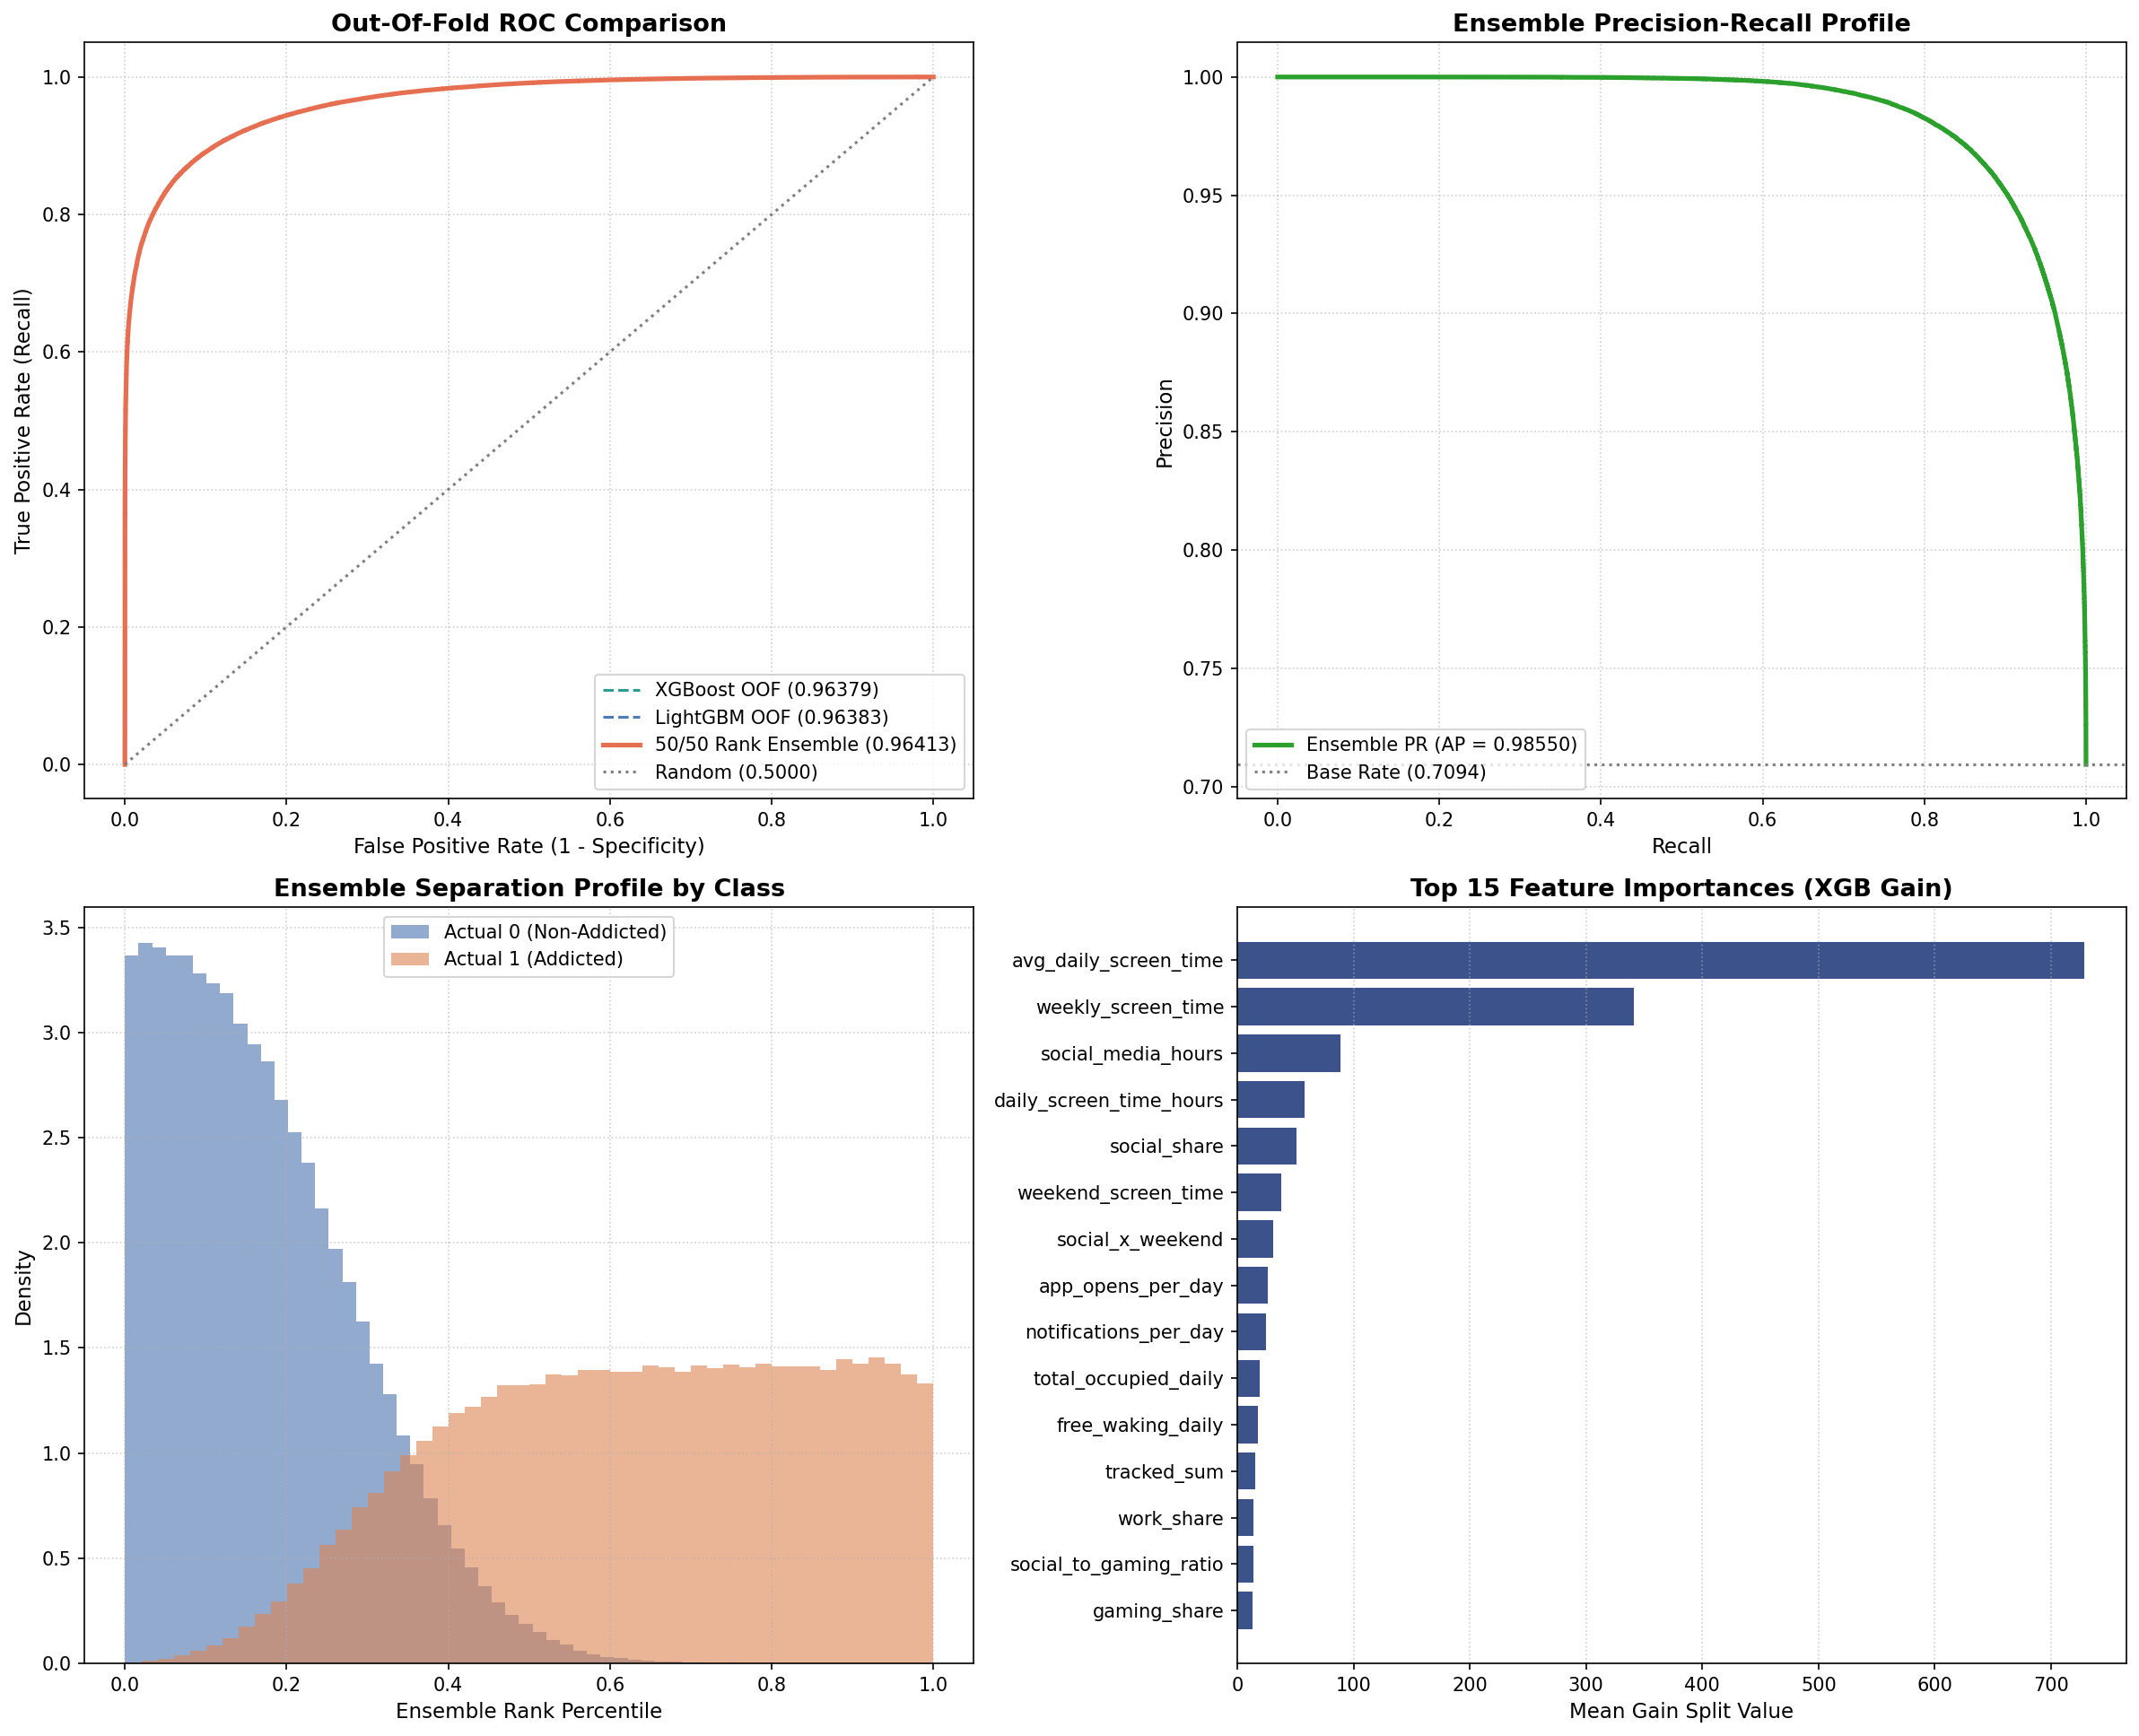


--- SUBMISSION SUMMARY ---
Total Rows:        296,302
Null Count:        0
Min Rank:          0.000003
Mean Rank:         0.500002
Max Rank:          1.000000


In [2]:
import os
from pathlib import Path
import pickle
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_curve, auc, roc_auc_score, precision_recall_curve, average_precision_score

import xgboost as xgb
from xgboost import XGBClassifier
import lightgbm as lgb
from lightgbm import LGBMClassifier

# ==============================================================================
# 1. DATA INGESTION
# ==============================================================================
candidate_paths = [
    Path('/kaggle/input/competitions/playground-series-s6e8'),
    Path('/kaggle/input/playground-series-s6e8'),
    Path('.')
]
DATA_DIR = next((p for p in candidate_paths if p.exists()), Path('.'))

train_raw = pd.read_csv(DATA_DIR / 'train.csv')
test_raw = pd.read_csv(DATA_DIR / 'test.csv')

print(f"[*] Loaded Raw Train: {train_raw.shape[0]:,} rows | Raw Test: {test_raw.shape[0]:,} rows")

# ==============================================================================
# 2. ADVANCED FEATURE ENGINEERING
# ==============================================================================
def advanced_feature_engineering(df: pd.DataFrame) -> tuple[pd.DataFrame, list, list]:
    data = df.copy()
    eps = 1e-4

    # 2.1 Categorical combinations (stored as clean strings for safe encoding)
    data['gender_stress'] = data['gender'].astype(str) + '_' + data['stress_level'].astype(str)
    data['stress_impact'] = data['stress_level'].astype(str) + '_' + data['academic_work_impact'].astype(str)
    data['all_cats'] = (
        data['gender'].astype(str) + '_' + 
        data['stress_level'].astype(str) + '_' + 
        data['academic_work_impact'].astype(str)
    )

    # 2.2 Time budget decomposition
    data['tracked_sum'] = (
        data['social_media_hours'].fillna(0) + 
        data['gaming_hours'].fillna(0) + 
        data['work_study_hours'].fillna(0)
    )
    data['unaccounted_daily'] = (
        data['daily_screen_time_hours'] - 
        (data['social_media_hours'] + data['gaming_hours'] + data['work_study_hours'])
    )
    data['leisure_screen_time'] = data['social_media_hours'].fillna(0) + data['gaming_hours'].fillna(0)

    # 2.3 Proportions & ratios
    data['social_share'] = data['social_media_hours'] / (data['daily_screen_time_hours'] + eps)
    data['gaming_share'] = data['gaming_hours'] / (data['daily_screen_time_hours'] + eps)
    data['work_share'] = data['work_study_hours'] / (data['daily_screen_time_hours'] + eps)
    data['tracked_ratio'] = data['tracked_sum'] / (data['daily_screen_time_hours'] + eps)
    data['leisure_to_work_ratio'] = (data['leisure_screen_time'] + eps) / (data['work_study_hours'].fillna(0) + eps)
    data['social_to_gaming_ratio'] = (data['social_media_hours'].fillna(0) + eps) / (data['gaming_hours'].fillna(0) + eps)

    # 2.4 Weekly dynamics & weekend surge
    data['weekend_lift'] = data['weekend_screen_time'] - data['daily_screen_time_hours']
    data['weekend_daily_ratio'] = data['weekend_screen_time'] / (data['daily_screen_time_hours'] + eps)
    data['weekly_screen_time'] = (5.0 * data['daily_screen_time_hours']) + (2.0 * data['weekend_screen_time'].fillna(data['daily_screen_time_hours']))
    data['avg_daily_screen_time'] = data['weekly_screen_time'] / 7.0

    # 2.5 Sleep & lifestyle disruption
    data['screen_to_sleep_ratio'] = data['daily_screen_time_hours'] / (data['sleep_hours'] + eps)
    data['total_occupied_daily'] = data['daily_screen_time_hours'] + data['sleep_hours'].fillna(7.0)
    data['free_waking_daily'] = 24.0 - data['total_occupied_daily']

    # 2.6 Density & interactions
    data['notifs_per_open'] = data['notifications_per_day'] / (data['app_opens_per_day'] + eps)
    data['screen_mins_per_open'] = (data['daily_screen_time_hours'] * 60.0) / (data['app_opens_per_day'] + eps)
    data['screen_x_opens'] = data['daily_screen_time_hours'] * data['app_opens_per_day'].fillna(0)
    data['social_x_weekend'] = data['social_media_hours'].fillna(0) * data['weekend_screen_time'].fillna(0)

    # 2.7 Missingness count
    raw_cols = [c for c in df.columns if c not in ['id', 'addicted_label']]
    data['missing_count'] = df[raw_cols].isnull().sum(axis=1)

    cat_columns = ['gender', 'stress_level', 'academic_work_impact', 'gender_stress', 'stress_impact', 'all_cats']
    te_columns = ['gender_stress', 'stress_impact', 'all_cats']

    return data, cat_columns, te_columns

print("[*] Generating domain features...")
train_df, cat_cols, te_cols = advanced_feature_engineering(train_raw)
test_df, _, _ = advanced_feature_engineering(test_raw)

# ==============================================================================
# 3. LEAK-FREE SMOOTHED OUT-OF-FOLD (OOF) TARGET ENCODING
# ==============================================================================
def apply_smoothed_target_encoding(train_data: pd.DataFrame, test_data: pd.DataFrame, target_cols: list, y_series: pd.Series, cv_splits, smoothing: float = 15.0):
    train_encoded = train_data.copy()
    test_encoded = test_data.copy()
    global_mean = float(y_series.mean())

    for col in target_cols:
        te_col_name = f"{col}_te"
        train_encoded[te_col_name] = 0.0
        test_fold_accum = np.zeros(len(test_data), dtype=np.float64)

        train_col_str = train_data[col].astype(str)
        test_col_str = test_data[col].astype(str)

        for trn_idx, val_idx in cv_splits:
            X_tr_col = train_col_str.iloc[trn_idx]
            y_tr = y_series.iloc[trn_idx]
            X_va_col = train_col_str.iloc[val_idx]

            # Compute smoothed Bayesian posterior means
            stats = pd.DataFrame({'cat': X_tr_col, 'target': y_tr})
            grouped = stats.groupby('cat')['target'].agg(['count', 'mean'])
            smoothed_series = ((grouped['count'] * grouped['mean']) + (smoothing * global_mean)) / (grouped['count'] + smoothing)
            smoothed_dict = smoothed_series.to_dict()

            # Vectorized dict lookup
            val_vals = X_va_col.map(smoothed_dict).fillna(global_mean).astype(np.float64).values
            train_encoded.iloc[val_idx, train_encoded.columns.get_loc(te_col_name)] = val_vals

            test_vals = test_col_str.map(smoothed_dict).fillna(global_mean).astype(np.float64).values
            test_fold_accum += test_vals / len(cv_splits)

        test_encoded[te_col_name] = test_fold_accum

    return train_encoded, test_encoded

# ==============================================================================
# 4. CROSS-VALIDATION SPLITS & PREPARATION
# ==============================================================================
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y = train_df['addicted_label']
cv_splits = list(skf.split(train_df, y))

print("[*] Computing leak-free OOF Target Encodings across 5 folds...")
train_df, test_df = apply_smoothed_target_encoding(train_df, test_df, te_cols, y, cv_splits, smoothing=15.0)

# Cast categorical columns to category dtype for native tree handling
for c in cat_cols:
    train_df[c] = train_df[c].astype('category')
    test_df[c] = test_df[c].astype('category')

features = [c for c in train_df.columns if c not in ['id', 'addicted_label']]
X = train_df[features]
X_test = test_df[features]

print(f"[*] Final Feature Count for Training: {len(features)}")

# ==============================================================================
# 5. MODEL CONFIGURATIONS (GPU-ACCELERATED)
# ==============================================================================
xgb_params = {
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'learning_rate': 0.03,
    'n_estimators': 3500,
    'max_depth': 7,
    'min_child_weight': 8,
    'subsample': 0.75,
    'colsample_bytree': 0.75,
    'reg_alpha': 0.5,
    'reg_lambda': 3.0,
    'gamma': 0.1,
    'tree_method': 'hist',
    'device': 'cuda',
    'enable_categorical': True,
    'early_stopping_rounds': 120,
    'random_state': 42
}

lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'learning_rate': 0.03,
    'n_estimators': 3500,
    'max_depth': 8,
    'num_leaves': 63,
    'min_child_samples': 30,
    'subsample': 0.75,
    'colsample_bytree': 0.75,
    'reg_alpha': 0.5,
    'reg_lambda': 3.0,
    'device': 'gpu',
    'random_state': 42,
    'verbose': -1
}

# ==============================================================================
# 6. 5-FOLD ENSEMBLE TRAINING (XGBOOST + LIGHTGBM)
# ==============================================================================
oof_xgb = np.zeros(len(train_df))
oof_lgb = np.zeros(len(train_df))
test_xgb = np.zeros(len(test_df))
test_lgb = np.zeros(len(test_df))

trained_xgb_models = []
trained_lgb_models = []

print("\n[*] Starting 5-Fold Training for XGBoost & LightGBM on GPU...")
for fold, (trn_idx, val_idx) in enumerate(cv_splits):
    X_tr, y_tr = X.iloc[trn_idx], y.iloc[trn_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

    # Train XGBoost
    model_xgb = XGBClassifier(**xgb_params)
    model_xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    oof_xgb[val_idx] = model_xgb.predict_proba(X_va)[:, 1]
    test_xgb += model_xgb.predict_proba(X_test)[:, 1] / 5.0
    trained_xgb_models.append(model_xgb)
    fold_auc_xgb = roc_auc_score(y_va, oof_xgb[val_idx])

    # Train LightGBM
    model_lgb = LGBMClassifier(**lgb_params)
    model_lgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(120, verbose=False)])
    oof_lgb[val_idx] = model_lgb.predict_proba(X_va)[:, 1]
    test_lgb += model_lgb.predict_proba(X_test)[:, 1] / 5.0
    trained_lgb_models.append(model_lgb)
    fold_auc_lgb = roc_auc_score(y_va, oof_lgb[val_idx])

    print(f"Fold {fold + 1} | XGB AUC: {fold_auc_xgb:.5f} | LGB AUC: {fold_auc_lgb:.5f}")

# ==============================================================================
# 7. RANK AVERAGING ENSEMBLE EVALUATION
# ==============================================================================
def to_ranks(probs: np.ndarray) -> np.ndarray:
    return rankdata(probs) / len(probs)

oof_rank_ensemble = (0.50 * to_ranks(oof_xgb)) + (0.50 * to_ranks(oof_lgb))
test_rank_ensemble = (0.50 * to_ranks(test_xgb)) + (0.50 * to_ranks(test_lgb))

xgb_overall_auc = roc_auc_score(y, oof_xgb)
lgb_overall_auc = roc_auc_score(y, oof_lgb)
ensemble_overall_auc = roc_auc_score(y, oof_rank_ensemble)

print("\n=======================================================")
print(f"  Overall OOF XGBoost AUC:        {xgb_overall_auc:.5f}")
print(f"  Overall OOF LightGBM AUC:       {lgb_overall_auc:.5f}")
print(f"  FINAL 50/50 RANK ENSEMBLE AUC:  {ensemble_overall_auc:.5f}")
print("=======================================================")

# ==============================================================================
# 8. SAVE CHECKPOINT (.PKL) & SUBMISSION (.CSV)
# ==============================================================================
checkpoint = {
    'xgb_models': trained_xgb_models,
    'lgb_models': trained_lgb_models,
    'features': features,
    'cat_cols': cat_cols,
    'te_cols': te_cols,
    'oof_xgb': oof_xgb,
    'oof_lgb': oof_lgb,
    'oof_rank_ensemble': oof_rank_ensemble,
    'test_rank_ensemble': test_rank_ensemble,
    'ensemble_auc': ensemble_overall_auc
}

pkl_path = '/kaggle/working/ensemble_xgb_lgb_checkpoint.pkl'
with open(pkl_path, 'wb') as f:
    pickle.dump(checkpoint, f)

submission = pd.DataFrame({
    'id': test_raw['id'].astype(int),
    'addicted_label': test_rank_ensemble
})
sub_path = '/kaggle/working/submission.csv'
submission.to_csv(sub_path, index=False)

print(f"\n[✓] Checkpoint saved:  '{pkl_path}'")
print(f"[✓] Submission saved:  '{sub_path}'")

# ==============================================================================
# 9. VISUAL DIAGNOSTICS DASHBOARD
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 13), dpi=150)

# Panel 1: ROC Curves
fpr_xgb, tpr_xgb, _ = roc_curve(y, oof_xgb)
fpr_lgb, tpr_lgb, _ = roc_curve(y, oof_lgb)
fpr_ens, tpr_ens, _ = roc_curve(y, oof_rank_ensemble)

axes[0, 0].plot(fpr_xgb, tpr_xgb, color='#2A9D8F', lw=1.5, linestyle='--', label=f'XGBoost OOF ({xgb_overall_auc:.5f})')
axes[0, 0].plot(fpr_lgb, tpr_lgb, color='#4A7BB7', lw=1.5, linestyle='--', label=f'LightGBM OOF ({lgb_overall_auc:.5f})')
axes[0, 0].plot(fpr_ens, tpr_ens, color='#E76F51', lw=2.5, label=f'50/50 Rank Ensemble ({ensemble_overall_auc:.5f})')
axes[0, 0].plot([0, 1], [0, 1], color='gray', linestyle=':', label='Random (0.5000)')
axes[0, 0].set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
axes[0, 0].set_ylabel('True Positive Rate (Recall)', fontsize=11)
axes[0, 0].set_title('Out-Of-Fold ROC Comparison', fontsize=13, fontweight='bold')
axes[0, 0].legend(loc='lower right', frameon=True)
axes[0, 0].grid(True, linestyle=':', alpha=0.6)

# Panel 2: Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y, oof_rank_ensemble)
pr_auc = average_precision_score(y, oof_rank_ensemble)
axes[0, 1].plot(recall, precision, color='#2ca02c', lw=2.5, label=f'Ensemble PR (AP = {pr_auc:.5f})')
axes[0, 1].axhline(y.mean(), color='gray', linestyle=':', label=f'Base Rate ({y.mean():.4f})')
axes[0, 1].set_xlabel('Recall', fontsize=11)
axes[0, 1].set_ylabel('Precision', fontsize=11)
axes[0, 1].set_title('Ensemble Precision-Recall Profile', fontsize=13, fontweight='bold')
axes[0, 1].legend(loc='lower left', frameon=True)
axes[0, 1].grid(True, linestyle=':', alpha=0.6)

# Panel 3: Probability Separation
axes[1, 0].hist(oof_rank_ensemble[y == 0], bins=50, alpha=0.6, color='#4C72B0', density=True, label='Actual 0 (Non-Addicted)')
axes[1, 0].hist(oof_rank_ensemble[y == 1], bins=50, alpha=0.6, color='#DD8452', density=True, label='Actual 1 (Addicted)')
axes[1, 0].set_xlabel('Ensemble Rank Percentile', fontsize=11)
axes[1, 0].set_ylabel('Density', fontsize=11)
axes[1, 0].set_title('Ensemble Separation Profile by Class', fontsize=13, fontweight='bold')
axes[1, 0].legend(loc='upper center', frameon=True)
axes[1, 0].grid(True, linestyle=':', alpha=0.6)

# Panel 4: Top 15 Features by XGBoost Gain
xgb_importances = pd.Series(0.0, index=features)
for m in trained_xgb_models:
    score = m.get_booster().get_score(importance_type='gain')
    xgb_importances = xgb_importances.add(pd.Series(score), fill_value=0.0)

top_features = (xgb_importances / len(trained_xgb_models)).sort_values(ascending=True).tail(15)
axes[1, 1].barh(top_features.index, top_features.values, color='#3b528b')
axes[1, 1].set_xlabel('Mean Gain Split Value', fontsize=11)
axes[1, 1].set_title('Top 15 Feature Importances (XGB Gain)', fontsize=13, fontweight='bold')
axes[1, 1].grid(True, axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('/kaggle/working/ensemble_visual_metrics.png', bbox_inches='tight')
plt.show()

print("\n--- SUBMISSION SUMMARY ---")
print(f"Total Rows:        {len(submission):,}")
print(f"Null Count:        {submission.isnull().sum().sum()}")
print(f"Min Rank:          {submission['addicted_label'].min():.6f}")
print(f"Mean Rank:         {submission['addicted_label'].mean():.6f}")
print(f"Max Rank:          {submission['addicted_label'].max():.6f}")